In [5]:
#The following function loads and pre-process the user-defined corpus from a specified path
#The function summarizes the steps discussed in notebook named 'Pre-processing Textual Data'
import os
import nltk
def load_corpus(path):
    #loads corpus as lsit of strings in content list
    filenames=os.listdir(path)
    documents=[]
    for i in range(len(filenames)):
        f=open(path+filenames[i])
        documents.append(f.read())
        f.close()
    return documents

In [6]:
path="C:/Users/jasme/Downloads/imdb_text_dataset/"
documents=load_corpus(path)
documents[0]

"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fa

In [7]:
#Normalize, Tokenize, and Stop-word removal    
from nltk.corpus import *
from nltk.stem import PorterStemmer
import re
ps=PorterStemmer()
stopword=nltk.corpus.stopwords.words('english')
def preprocess(text):
    text=text.lower()
    text=re.sub(r'<.+?>',' ',text) #remove tags
    text=re.sub(r'https?://\S+|www\.\S+',' ',text) #remove URLS
    text=re.sub(r'\S@[a-zA-Z0-9]+\.[a-zA-Z]{2,}',' ',text ) #remove email ids
    text=re.sub(r'[^a-zA-Z0-9]',' ',text) #keep characters and numbers onl
    text=re.sub(r'\s+',' ',text) #remove extra white spaces
    text=[word for word in nltk.word_tokenize(text) if word not in stopword]
    text=' '.join([ps.stem(word) for word in text])
    return text
    

In [9]:
preprocessed_docs=[]
for doc in documents:
    preprocessed_docs.append(preprocess(doc))
preprocessed_docs[0]

'one review mention watch 1 oz episod hook right exactli happen first thing struck oz brutal unflinch scene violenc set right word go trust show faint heart timid show pull punch regard drug sex violenc hardcor classic use word call oz nicknam given oswald maximum secur state penitentari focus mainli emerald citi experiment section prison cell glass front face inward privaci high agenda em citi home mani aryan muslim gangsta latino christian italian irish scuffl death stare dodgi deal shadi agreement never far away would say main appeal show due fact goe show dare forget pretti pictur paint mainstream audienc forget charm forget romanc oz mess around first episod ever saw struck nasti surreal say readi watch develop tast oz got accustom high level graphic violenc violenc injustic crook guard sold nickel inmat kill order get away well manner middl class inmat turn prison bitch due lack street skill prison experi watch oz may becom comfort uncomfort view that get touch darker side'

# Pre-processed Corpus to Feature Matrix
After pre-processing the text (documents) of the corpus, we can construct feature matrix from the pre-processed corpus and hence convert the unstructured data to structured form.

Following two types of feature matrix are broadly used for textual data:
1. Term-Document Matrix (TDM)/ Document-Term Matrix (DTM)/Bag-of-Words (BoW)
2. Term-Term Matrix (TTM)/Co-occurrence matrix 


# Variants of TDM
Depending upon how the ijth entry of the TDM matrix is filled, there are different variants of TDM matrix:
1. Binary
2. Term Frequency
3. Term Frequency with length normalization
4. Term Frequency wit maximum normalization
5. Term Frequency with log normalization
6. Term Frequency-Inverse Document Frequency

# Variant 1: Binary TDM

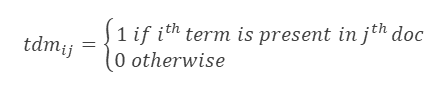

In [10]:
#Binary TDM from Scratch
path="C:/Users/jasme/Downloads/imdb_text_dataset/"
filenames=os.listdir(path)
doc_count={} #dictionary for each document
for i in range(len(preprocessed_docs)):
    word_count={} #dictionary for words for each document
    for word in preprocessed_docs[i].split():
        if word not in word_count.keys():
            word_count[word]=1
    doc_count[filenames[i]]=word_count
doc_count


{'review_1.txt': {'one': 1,
  'review': 1,
  'mention': 1,
  'watch': 1,
  '1': 1,
  'oz': 1,
  'episod': 1,
  'hook': 1,
  'right': 1,
  'exactli': 1,
  'happen': 1,
  'first': 1,
  'thing': 1,
  'struck': 1,
  'brutal': 1,
  'unflinch': 1,
  'scene': 1,
  'violenc': 1,
  'set': 1,
  'word': 1,
  'go': 1,
  'trust': 1,
  'show': 1,
  'faint': 1,
  'heart': 1,
  'timid': 1,
  'pull': 1,
  'punch': 1,
  'regard': 1,
  'drug': 1,
  'sex': 1,
  'hardcor': 1,
  'classic': 1,
  'use': 1,
  'call': 1,
  'nicknam': 1,
  'given': 1,
  'oswald': 1,
  'maximum': 1,
  'secur': 1,
  'state': 1,
  'penitentari': 1,
  'focus': 1,
  'mainli': 1,
  'emerald': 1,
  'citi': 1,
  'experiment': 1,
  'section': 1,
  'prison': 1,
  'cell': 1,
  'glass': 1,
  'front': 1,
  'face': 1,
  'inward': 1,
  'privaci': 1,
  'high': 1,
  'agenda': 1,
  'em': 1,
  'home': 1,
  'mani': 1,
  'aryan': 1,
  'muslim': 1,
  'gangsta': 1,
  'latino': 1,
  'christian': 1,
  'italian': 1,
  'irish': 1,
  'scuffl': 1,
  'death'

In [11]:
#Converting dictionary to a TDM dataframe
import pandas as pd
binary_tdm_scratch=pd.DataFrame(doc_count)
binary_tdm_scratch.fillna(0,inplace=True)
binary_tdm_scratch=binary_tdm_scratch.sort_index()
binary_tdm_scratch

,review_1.txt,review_10.txt,review_100.txt,review_101.txt,review_102.txt,review_103.txt,review_104.txt,review_105.txt,review_106.txt,review_107.txt,...,review_90.txt,review_91.txt,review_92.txt,review_93.txt,review_94.txt,review_95.txt,review_96.txt,review_97.txt,review_98.txt,review_99.txt
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
00am,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
zombi,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
zone,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
zoo,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
zoom,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [18]:
#Binary TDM using In-built function called CountVectorizer() class of sklearn.feature_extraction.text class

#Syntax: sklearn.feature_extraction.text.CountVectorizer
#(*, input='content', encoding='utf-8', decode_error='strict', 
#strip_accents=None, lowercase=True, preprocessor=None, tokenizer=None,
#stop_words=None, token_pattern='(?u)\b\w\w+\b', ngram_range=(1, 1), 
#analyzer='word', max_df=1.0, min_df=1, max_features=None,
#vocabulary=None, binary=False, dtype=<class 'numpy.int64'>)

#For binary TDM set binary=True
from sklearn.feature_extraction.text import CountVectorizer
cv=CountVectorizer(binary=True,token_pattern='(?u)\\b\\w+\\b')
X=cv.fit_transform(preprocessed_docs) # returns a binary tdm in compressed sparse row format
print(X)

  (0, 3500)	1
  (0, 4172)	1
  (0, 3131)	1
  (0, 5456)	1
  (0, 4)	1
  (0, 3579)	1
  (0, 1685)	1
  (0, 2389)	1
  (0, 4193)	1
  (0, 1732)	1
  (0, 2251)	1
  (0, 1879)	1
  (0, 5036)	1
  (0, 4820)	1
  (0, 717)	1
  (0, 5253)	1
  (0, 4340)	1
  (0, 5393)	1
  (0, 4432)	1
  (0, 5560)	1
  (0, 2117)	1
  (0, 5176)	1
  (0, 4501)	1
  (0, 1790)	1
  (0, 2294)	1
  :	:
  (199, 1862)	1
  (199, 1056)	1
  (199, 2015)	1
  (199, 3357)	1
  (199, 4763)	1
  (199, 5275)	1
  (199, 5608)	1
  (199, 3240)	1
  (199, 96)	1
  (199, 2460)	1
  (199, 4295)	1
  (199, 2075)	1
  (199, 2764)	1
  (199, 3845)	1
  (199, 1431)	1
  (199, 4079)	1
  (199, 5423)	1
  (199, 747)	1
  (199, 4924)	1
  (199, 1940)	1
  (199, 2909)	1
  (199, 2052)	1
  (199, 1307)	1
  (199, 627)	1
  (199, 5165)	1


In [19]:
#Converting X to TDM DataFrame
binary_tdm_inbuilt=pd.DataFrame(X.toarray().T,index=cv.get_feature_names(),columns=filenames)
binary_tdm_inbuilt

,review_1.txt,review_10.txt,review_100.txt,review_101.txt,review_102.txt,review_103.txt,review_104.txt,review_105.txt,review_106.txt,review_107.txt,...,review_90.txt,review_91.txt,review_92.txt,review_93.txt,review_94.txt,review_95.txt,review_96.txt,review_97.txt,review_98.txt,review_99.txt
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
000,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
00am,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
zombi,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
zone,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
zoo,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
zoom,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


# Variant 2: Term Frequency TDM

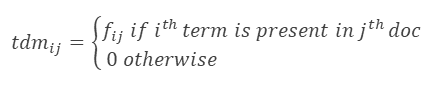

In [20]:
# Term frequency TDM from scratch
path="C:/Users/jasme/Downloads/imdb_text_dataset/"
filenames=os.listdir(path)
doc_count1={} #dictionary for each document
for i in range(len(preprocessed_docs)):
    word_count1={} #dictionary for words for each document
    for word in preprocessed_docs[i].split():
        if word not in word_count1.keys():
            word_count1[word]=0
        word_count1[word]+=1
    doc_count1[filenames[i]]=word_count1
doc_count1


{'review_1.txt': {'one': 1,
  'review': 1,
  'mention': 1,
  'watch': 3,
  '1': 1,
  'oz': 6,
  'episod': 2,
  'hook': 1,
  'right': 2,
  'exactli': 1,
  'happen': 1,
  'first': 2,
  'thing': 1,
  'struck': 2,
  'brutal': 1,
  'unflinch': 1,
  'scene': 1,
  'violenc': 4,
  'set': 1,
  'word': 2,
  'go': 1,
  'trust': 1,
  'show': 4,
  'faint': 1,
  'heart': 1,
  'timid': 1,
  'pull': 1,
  'punch': 1,
  'regard': 1,
  'drug': 1,
  'sex': 1,
  'hardcor': 1,
  'classic': 1,
  'use': 1,
  'call': 1,
  'nicknam': 1,
  'given': 1,
  'oswald': 1,
  'maximum': 1,
  'secur': 1,
  'state': 1,
  'penitentari': 1,
  'focus': 1,
  'mainli': 1,
  'emerald': 1,
  'citi': 2,
  'experiment': 1,
  'section': 1,
  'prison': 3,
  'cell': 1,
  'glass': 1,
  'front': 1,
  'face': 1,
  'inward': 1,
  'privaci': 1,
  'high': 2,
  'agenda': 1,
  'em': 1,
  'home': 1,
  'mani': 1,
  'aryan': 1,
  'muslim': 1,
  'gangsta': 1,
  'latino': 1,
  'christian': 1,
  'italian': 1,
  'irish': 1,
  'scuffl': 1,
  'death'

In [21]:
#Converting dictionary to term frequency TDM dataframe
tdm_tf_scratch=pd.DataFrame(doc_count1)
tdm_tf_scratch.fillna(0,inplace=True)
tdm_tf_scratch=tdm_tf_scratch.sort_index()
tdm_tf_scratch

,review_1.txt,review_10.txt,review_100.txt,review_101.txt,review_102.txt,review_103.txt,review_104.txt,review_105.txt,review_106.txt,review_107.txt,...,review_90.txt,review_91.txt,review_92.txt,review_93.txt,review_94.txt,review_95.txt,review_96.txt,review_97.txt,review_98.txt,review_99.txt
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
00am,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
zombi,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
zone,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
zoo,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
zoom,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [23]:
# Term frequency TDM using CountVectorizer of Sklearn library
from sklearn.feature_extraction.text import CountVectorizer
cv1=CountVectorizer(token_pattern='(?u)\\b\\w+\\b')
Y=cv1.fit_transform(preprocessed_docs) # returns a term frequency tdm in compressed sparse row (csr) format 
print(Y)

  (0, 3500)	1
  (0, 4172)	1
  (0, 3131)	1
  (0, 5456)	3
  (0, 4)	1
  (0, 3579)	6
  (0, 1685)	2
  (0, 2389)	1
  (0, 4193)	2
  (0, 1732)	1
  (0, 2251)	1
  (0, 1879)	2
  (0, 5036)	1
  (0, 4820)	2
  (0, 717)	1
  (0, 5253)	1
  (0, 4340)	1
  (0, 5393)	4
  (0, 4432)	1
  (0, 5560)	2
  (0, 2117)	1
  (0, 5176)	1
  (0, 4501)	4
  (0, 1790)	1
  (0, 2294)	1
  :	:
  (199, 1862)	1
  (199, 1056)	1
  (199, 2015)	1
  (199, 3357)	1
  (199, 4763)	1
  (199, 5275)	1
  (199, 5608)	1
  (199, 3240)	1
  (199, 96)	1
  (199, 2460)	1
  (199, 4295)	1
  (199, 2075)	1
  (199, 2764)	1
  (199, 3845)	1
  (199, 1431)	1
  (199, 4079)	1
  (199, 5423)	1
  (199, 747)	1
  (199, 4924)	1
  (199, 1940)	1
  (199, 2909)	2
  (199, 2052)	2
  (199, 1307)	1
  (199, 627)	1
  (199, 5165)	1


In [24]:
# Converting csr format to dataframe
tdm_tf_inbuilt=pd.DataFrame(Y.toarray().T,index=cv1.get_feature_names(),columns=filenames)
tdm_tf_inbuilt

,review_1.txt,review_10.txt,review_100.txt,review_101.txt,review_102.txt,review_103.txt,review_104.txt,review_105.txt,review_106.txt,review_107.txt,...,review_90.txt,review_91.txt,review_92.txt,review_93.txt,review_94.txt,review_95.txt,review_96.txt,review_97.txt,review_98.txt,review_99.txt
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
000,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
00am,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
zombi,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
zone,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
zoo,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
zoom,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
